# 05 - The full benchmark: v3 and v4 against QUANT + ExtraTrees and the published classifiers

v3 and v4 on the paper's 142 datasets x 30 resamples: against QUANT + ExtraTrees (v1), on the 108 datasets never used in development, and against the
published classifiers of the bake-off redux. Covered: the protocol and what could make it optimistic (1b), simple baselines (2b), time and memory (4, 4b)
the default split alone (5b), Friedman's test and the critical-difference diagram (6), v4 against every other classifier (6c), accuracy against cost (6d),
seeds (7b), every metric and confusion matrices (8b, 8c).

## 1. Data

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from common import (BETTER, EQUAL, GROUP_COLORS, MUTED, OTHERS, PHASE_COLORS, REPO, RESULTS_DIR, TEXT, VERSION_COLORS,
                    WARNING, WORSE, change_color, dataset_list, holm, load_runs, signed, style, wdl_counts)

style()
NAMES = {"v1": "QUANT + ExtraTrees (v1)", "v3": "v3 (cheap TabPFN)", "v4": "v4 (supervised extractor)"}
RESULT_COLORS = VERSION_COLORS                      # one colour per result (notebooks/common.py)
DATASETS = (REPO / "original" / "code" / "ucr142.txt").read_text().split()   # the 142 datasets of the paper

v1_runs = load_runs(RESULTS_DIR / "v1_ucr142_onecore-cpu.csv")      # one row per run
v1_all_runs = load_runs(RESULTS_DIR / "v1_ucr142_allcores-cpu.csv")  # the same method on all CPU cores
v3_runs = load_runs(RESULTS_DIR / "v3_tabpfn-e2f200-both_ucr142_allcores-gpu.csv")   # notebook 03
v4_runs = load_runs(RESULTS_DIR / "v4_tabpfn-e2f200_ucr142_allcores-gpu.csv")        # notebook 04

def wide(runs):
    """One row per dataset (in the order of the paper's list), one column per resample."""
    return runs.pivot(index="dataset", columns="resample", values="accuracy").loc[DATASETS]

ACCURACY = {"v1": wide(v1_runs), "v3": wide(v3_runs), "v4": wide(v4_runs)}
MEAN = pd.DataFrame({name: table.mean(axis=1) for name, table in ACCURACY.items()})   # mean of the 30 per dataset
# checks (an error here means a results file is incomplete)
for runs in (v1_runs, v1_all_runs, v3_runs, v4_runs):
    assert len(runs) == 142 * 30 and (runs["status"] == "ok").all()
assert (wide(v1_all_runs) == ACCURACY["v1"]).all().all()     # all cores: the same accuracy as one core, in every run

## 1b. The protocol, and what could make the results optimistic

- **Splits:** 142 datasets x 30 resamples: resample 0 is the archive's own split, 1 to 29 the bake-off redux's
  stratified resamples, so every comparison with the published classifiers is paired split by split.
- **Training data only:** every step that learns (v4's feature checks, ranking, lags, templates; v3's feature choice;
  TabPFN's preprocessing) is fitted on the training split; the test split only goes through `transform` and `predict`.
- **Development datasets:** v3's and v4's settings were chosen on the test accuracy of 34 datasets (`dev34.txt`), so
  the other 108 are reported separately.
- **Shuffled resamples:** resamples 1-29 can put the same subject in training and test data and look better than they
  are, so resample 0 is reported alone.
- **Statistics:** one value per dataset (the mean of its 30 resamples); two-sided Wilcoxon signed-rank tests,
  alpha = 0.05, Holm's correction per family of tests; Friedman's test before the pairwise comparisons.
- **Seeds:** one seed per resample in the full runs, five seeds on resample 0.
- **Not run by us:** the published classifiers' results (the bake-off redux's own) and TabPFN's pretraining.

## 2. Mean accuracy and mean rank

Each dataset = the mean of its 30 resamples; rank 1 = the most accurate on a dataset.

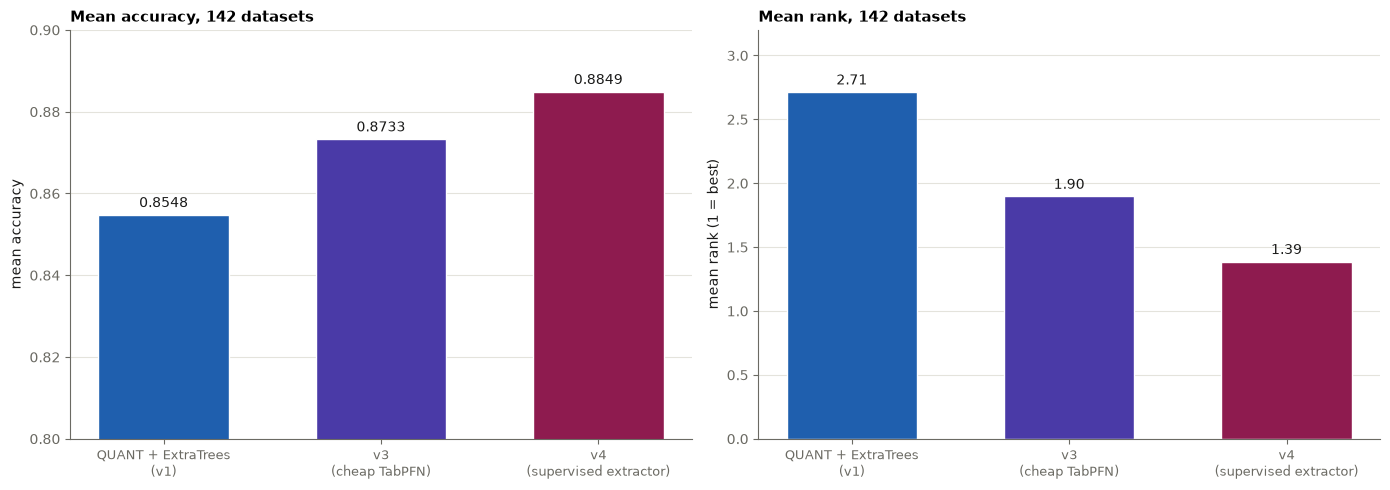

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
bars = ax.bar(range(len(NAMES)), MEAN[list(NAMES)].mean(), 0.6, color=[RESULT_COLORS[n] for n in NAMES],
              edgecolor="white")
ax.bar_label(bars, fmt="{:.4f}", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
ax.set_ylim(0.80, 0.90)
ax.set_ylabel("mean accuracy")
ax.set_title("Mean accuracy, 142 datasets", loc="left")

ax = axes[1]
ranks = MEAN.rank(axis=1, ascending=False).mean()       # 1 = the most accurate on a dataset
bars = ax.bar(range(len(NAMES)), [ranks[n] for n in NAMES], 0.6, color=[RESULT_COLORS[n] for n in NAMES],
              edgecolor="white")
ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
ax.set_ylim(0, 3.2)
ax.set_ylabel("mean rank (1 = best)")
ax.set_title("Mean rank, 142 datasets", loc="left")
fig.tight_layout()
plt.show()

## 2b. The simple baselines

We compare: 
Simple classifiers (the most frequent training class, ExtraTrees on the raw values (one feature per time point), and catch22 with a random forest (the statistics baseline); TabPFN (2 passes, the GPU) on the raw values, to shows what v4 extractor adds; 1NN-DTW; and ROCKET on the same 142 datasets x 30 resamples.

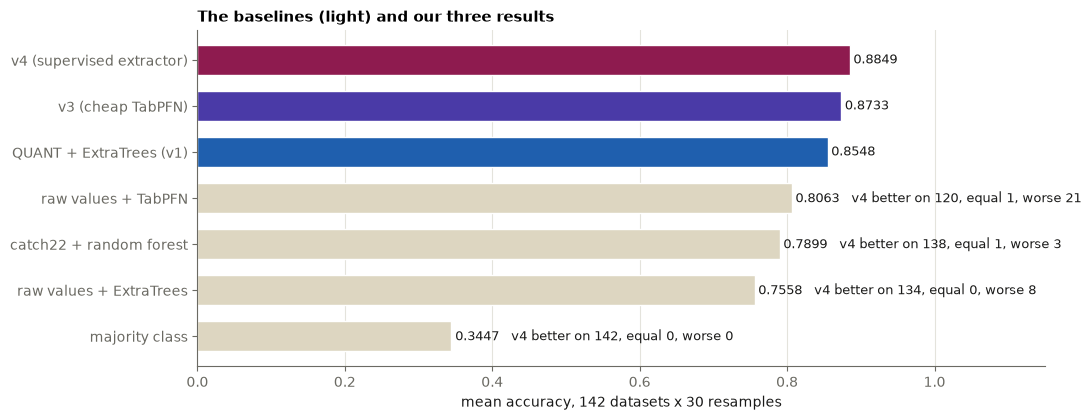

In [ ]:
BASELINE_NAMES = {"majority": "majority class", "raw": "raw values + ExtraTrees", "catch22": "catch22 + random forest",
                  "tabpfn": "raw values + TabPFN"}           # tabpfn: v4's classifier on the series, without v4's extractor
BASELINE_COLOR = "#ddd6c1"                                  # the baselines: light
base_runs = pd.concat([load_runs(RESULTS_DIR / "baselines_ucr142_allcores-cpu.csv"),        # the first three
                       load_runs(RESULTS_DIR / "baselines-tabpfn_ucr142_allcores-gpu.csv")],  # TabPFN
                      ignore_index=True)
assert len(base_runs) == 4 * 142 * 30 and (base_runs["status"] == "ok").all()
BASE_MEAN = pd.DataFrame(index=DATASETS)                    # one column per baseline: its mean accuracy per dataset
for key, label in BASELINE_NAMES.items():
    BASE_MEAN[label] = base_runs[base_runs["classifier"] == key].groupby("dataset")["accuracy"].mean()

OURS = list(NAMES.values())                                 # our three results, by their long names
CODE_OF = {long: short for short, long in NAMES.items()}   # long name -> "v1", "v3" or "v4"


def color_of(name):
    """Our results in their colours, the baselines light, the published classifiers grey."""
    if name in OURS:
        return RESULT_COLORS[CODE_OF[name]]
    if name in BASE_MEAN:
        return BASELINE_COLOR
    return OTHERS


ours_mean = MEAN[list(NAMES)].mean().rename(NAMES)           # rename: "v1" -> its long name
order = pd.concat([BASE_MEAN.mean(), ours_mean]).sort_values()
fig, ax = plt.subplots(figsize=(11, 4.3))
bars = ax.barh(range(len(order)), order, 0.65, color=[color_of(n) for n in order.index], edgecolor="white")
for y, (name, value) in enumerate(order.items()):
    note = ""
    if name in BASE_MEAN:
        better, equal, worse = wdl_counts(MEAN["v4"] - BASE_MEAN[name])
        note = f"   v4 better on {better}, equal {equal}, worse {worse}"
    ax.text(value + 0.005, y, f"{value:.4f}{note}", va="center", fontsize=9, color=TEXT)
ax.set_yticks(range(len(order)), order.index)
ax.set_xlim(0, 1.15)
ax.set_xlabel("mean accuracy, 142 datasets x 30 resamples")
ax.set_title("The baselines (light) and our three results", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## 3. Per dataset: v3 and v4 vs QUANT + ExtraTrees, and v4 vs v3

Left: one point per dataset; above the diagonal the first-named result is more accurate. Right: the change on every
dataset, sorted, with the Wilcoxon signed-rank p-value.

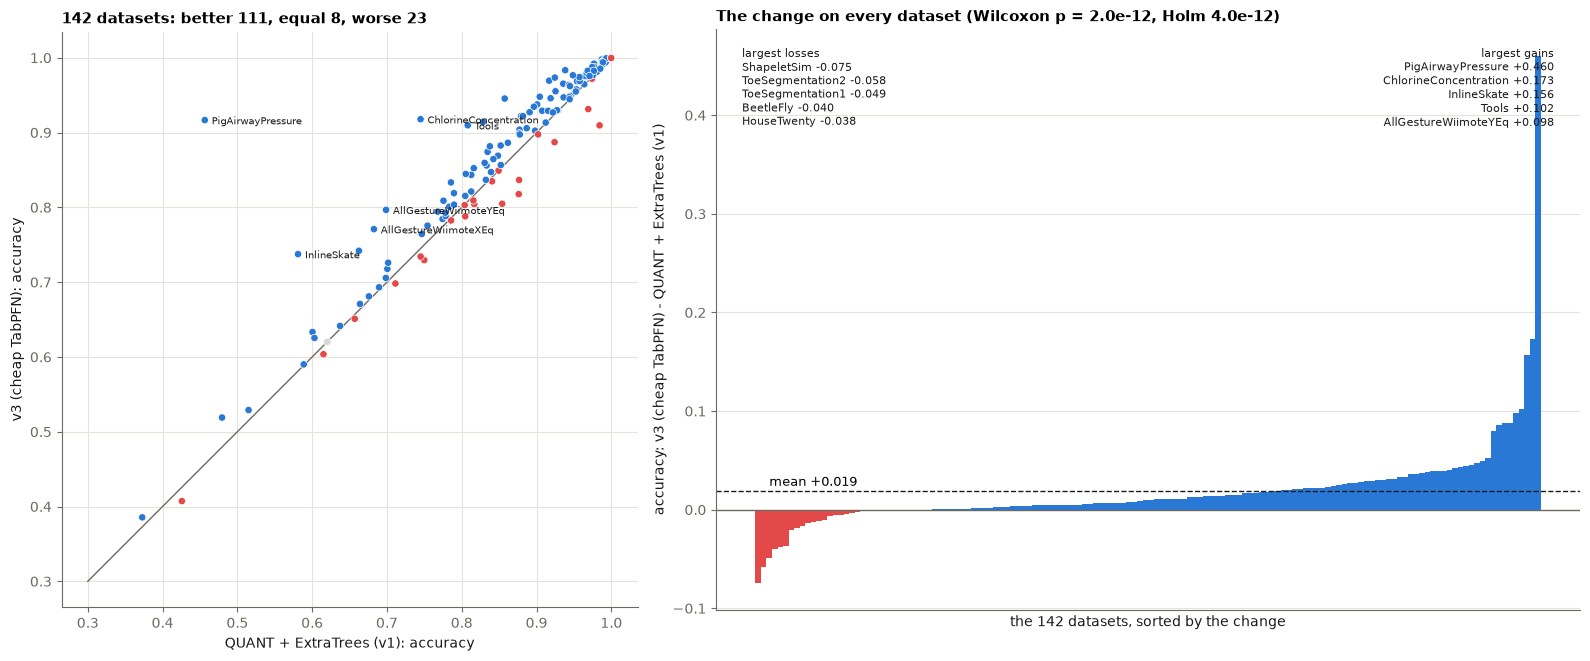

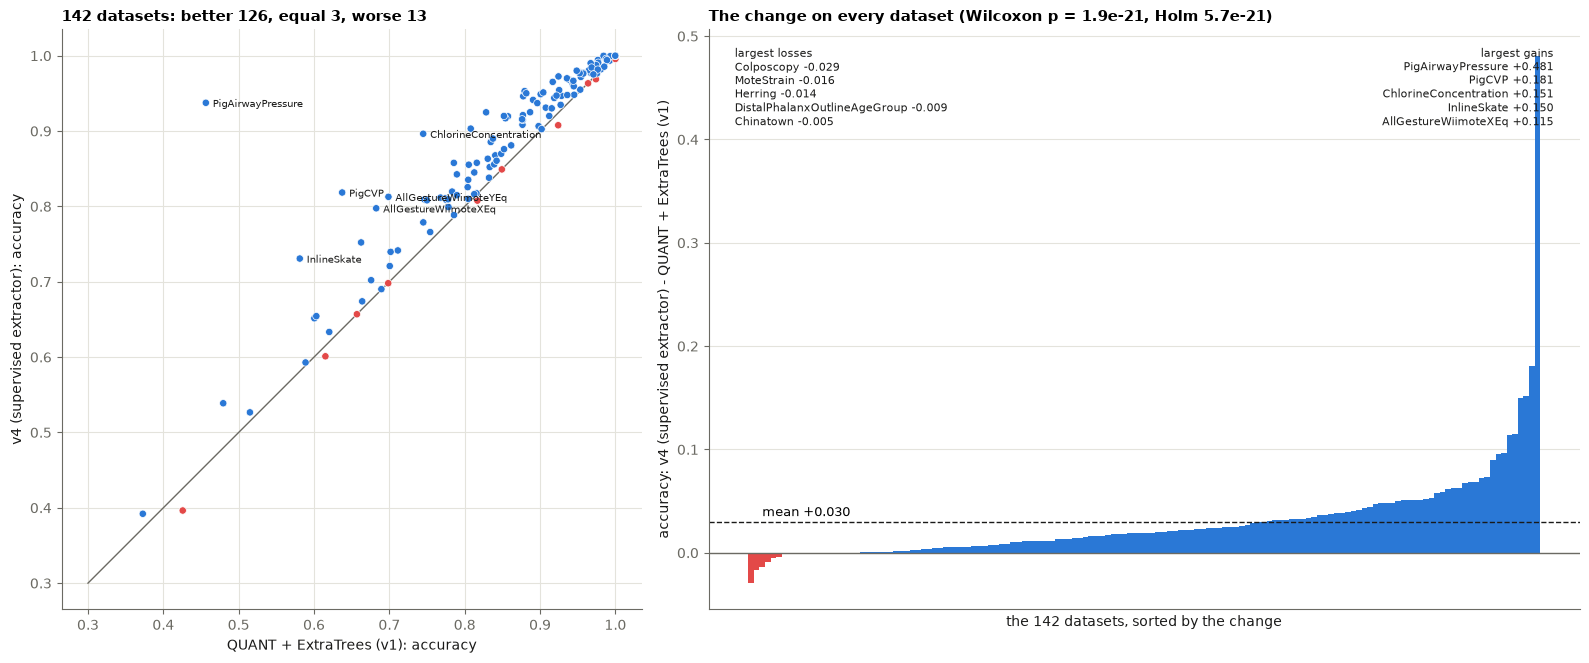

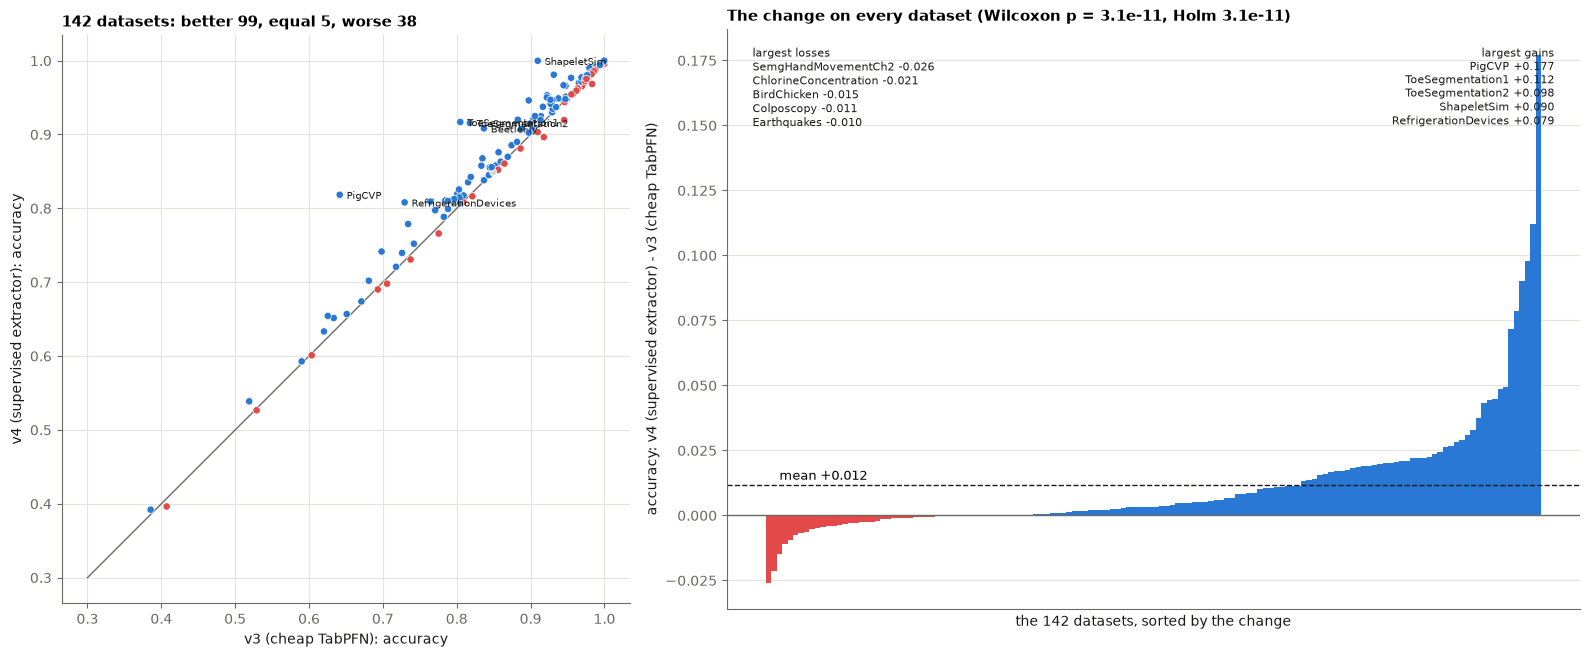

In [4]:
# the three Wilcoxon tests, and Holm's correction over the three
PAIRS = [("v3", "v1"), ("v4", "v1"), ("v4", "v3")]
P_RAW = pd.Series({f"{a} vs {b}": stats.wilcoxon(MEAN[a], MEAN[b]).pvalue for a, b in PAIRS})
P_HOLM = holm(P_RAW)


def compare(a, b):
    """The per-dataset comparison of result a against result b (all 142 datasets): one row of plots."""
    change = MEAN[a] - MEAN[b]
    better, equal, worse = wdl_counts(change)
    colors = [change_color(x) for x in change]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.5]})
    ax = axes[0]
    ax.plot([0.3, 1.0], [0.3, 1.0], color=MUTED, linewidth=1, zorder=1)    # the diagonal: equal accuracy
    ax.scatter(MEAN[b], MEAN[a], s=28, c=colors, edgecolor="white", linewidth=0.5, zorder=3)
    for name in change.abs().sort_values().index[-6:]:                     # the 6 largest changes, named
        ax.annotate(name, (MEAN.loc[name, b], MEAN.loc[name, a]), xytext=(5, -3), textcoords="offset points",
                    fontsize=7.5, color=TEXT)
    ax.set_xlabel(f"{NAMES[b]}: accuracy")
    ax.set_ylabel(f"{NAMES[a]}: accuracy")
    ax.set_title(f"142 datasets: better {better}, equal {equal}, worse {worse}", loc="left")
    ax.grid(True, axis="both")
    ax.set_aspect("equal")

    ax = axes[1]
    order = change.sort_values()
    ax.bar(range(len(order)), order, 1.0, color=[change_color(x) for x in order])
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axhline(change.mean(), color=TEXT, linewidth=1, linestyle="--")
    ax.annotate(f"mean {signed(change.mean())}", (2, change.mean()), xytext=(0, 4), textcoords="offset points", fontsize=9)
    gains = [f"{n} {signed(x)}" for n, x in order.tail(5).items()][::-1]     # the 5 largest gains, largest first
    losses = [f"{n} {signed(x)}" for n, x in order.head(5).items()]           # the 5 largest losses
    gains, losses = "\n".join(gains), "\n".join(losses)
    ax.text(0.97, 0.97, f"largest gains\n{gains}", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=TEXT)
    ax.text(0.03, 0.97, f"largest losses\n{losses}", transform=ax.transAxes, ha="left", va="top", fontsize=8, color=TEXT)
    ax.set_xticks([])
    ax.set_xlabel("the 142 datasets, sorted by the change")
    ax.set_ylabel(f"accuracy: {NAMES[a]} - {NAMES[b]}")
    test = f"{a} vs {b}"
    ax.set_title(f"The change on every dataset (Wilcoxon p = {P_RAW[test]:.1e}, Holm {P_HOLM[test]:.1e})", loc="left")
    fig.tight_layout()
    plt.show()

for a, b in PAIRS:
    compare(a, b)

## 4. Time per run

Transforms + feature selection + fit + predict. QUANT + ExtraTrees on one core (the paper's setting) and on all cores
(the fair comparison: the same cores as v3 and v4, which also use the GPU).

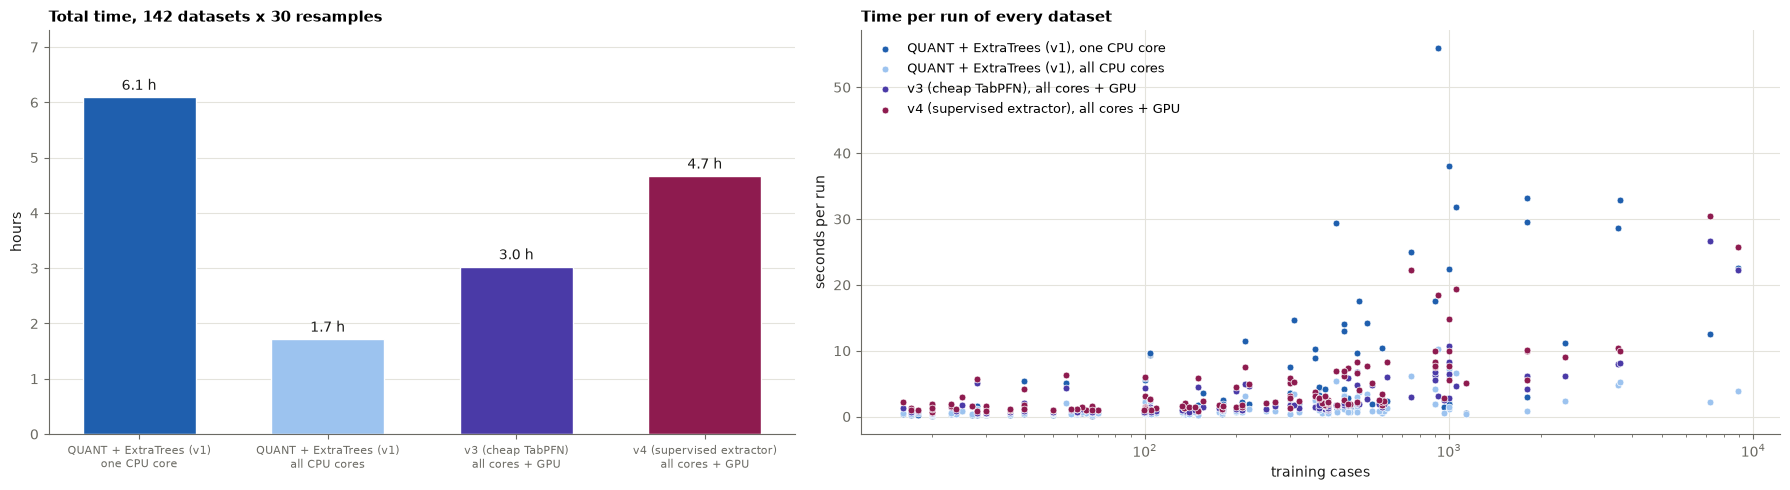

In [5]:
n_train = v3_runs.groupby("dataset")["n_train"].first()               # training cases of every dataset
RUNS = {"v1": v1_runs, "v1 all cores": v1_all_runs, "v3": v3_runs, "v4": v4_runs}
LABELS = {"v1": "QUANT + ExtraTrees (v1)\none CPU core", "v1 all cores": "QUANT + ExtraTrees (v1)\nall CPU cores",
          "v3": "v3 (cheap TabPFN)\nall cores + GPU", "v4": "v4 (supervised extractor)\nall cores + GPU"}
time = pd.DataFrame({name: runs.groupby("dataset")["total_time"].mean() for name, runs in RUNS.items()}).loc[DATASETS]
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.3, 1.6]})
ax = axes[0]
totals = [runs["total_time"].sum() / 3600 for runs in RUNS.values()]
bars = ax.bar(range(len(RUNS)), totals, 0.6, color=[RESULT_COLORS[n] for n in RUNS], edgecolor="white")
ax.bar_label(bars, fmt="{:.1f} h", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(RUNS)), [LABELS[n] for n in RUNS], fontsize=8)
ax.set_ylim(0, max(totals) * 1.2)
ax.set_ylabel("hours")
ax.set_title("Total time, 142 datasets x 30 resamples", loc="left")

ax = axes[1]
for name in RUNS:
    ax.scatter(n_train[time.index], time[name], s=24, color=RESULT_COLORS[name], edgecolor="white",
               linewidth=0.5, label=LABELS[name].replace("\n", ", "), zorder=3)
ax.set_xscale("log")
ax.set_xlabel("training cases")
ax.set_ylabel("seconds per run")
ax.set_title("Time per run of every dataset", loc="left")
ax.grid(True, axis="both")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4b. Where the time goes, and memory

Left: the hours of the full runs by phase. TabPFN learns nothing in `fit` (it only stores the training cases); its work
is in `predict`, so for v3 and v4 the prediction dominates, unlike for the trees. v4's feature selection is part of its
training transform. Right: the peak memory of every run of resample 0 (seed 0): the RAM of the whole process (it
includes TabPFN's model and the CUDA runtime, about 6 GB on its own) and the GPU memory PyTorch allocated.

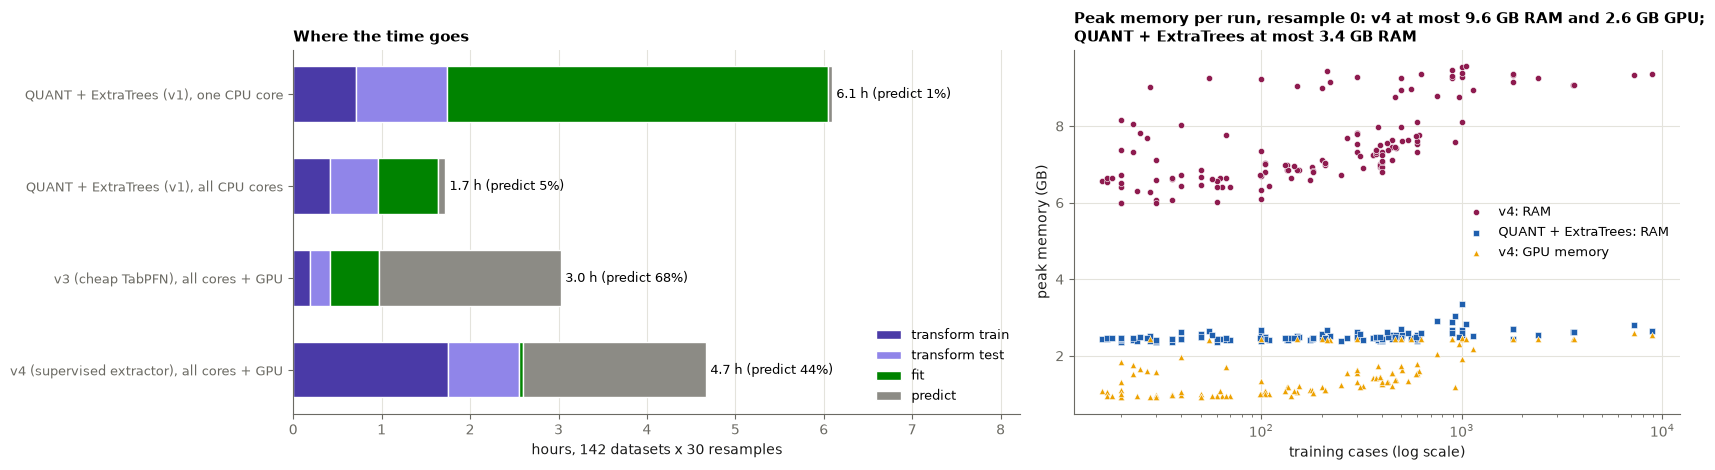

In [6]:
PHASE_COLUMNS = {"transform train": ["time_transform_train", "time_lag_train", "time_select"],
                 "transform test": ["time_transform_test", "time_lag_test"], "fit": ["time_fit"], "predict": ["time_predict"]}
PHASE_RUNS = {"v1": v1_runs, "v1 all cores": v1_all_runs, "v3": v3_runs, "v4": v4_runs}
hours = pd.DataFrame(index=list(PHASE_RUNS), columns=list(PHASE_COLUMNS), dtype=float)   # one row per result
for name, runs in PHASE_RUNS.items():
    for phase, columns in PHASE_COLUMNS.items():
        hours.loc[name, phase] = runs[columns].sum().sum() / 3600      # seconds -> hours

seed_runs = {"v1": load_runs(RESULTS_DIR / "v1-seeds_extratrees_ucr142-r0_allcores-cpu.csv"),
             "v4": load_runs(RESULTS_DIR / "v4-seeds_tabpfn-e2f200_ucr142-r0_allcores-gpu.csv")}
seed0 = {}                                               # seed 0: one row per dataset
for name, runs in seed_runs.items():
    seed0[name] = runs[(runs["seed"] == 0) & (runs["status"] == "ok")].set_index("dataset").loc[DATASETS]

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
left = np.zeros(len(hours))
for phase in PHASE_COLUMNS:
    ax.barh(range(len(hours)), hours[phase], 0.6, left=left, color=PHASE_COLORS[phase], label=phase, edgecolor="white")
    left += hours[phase].values
for y, total in enumerate(left):
    ax.text(total + 0.05, y, f"{total:.1f} h (predict {hours['predict'].iloc[y] / total:.0%})", va="center", fontsize=9)
ax.set_yticks(range(len(hours)), [LABELS[n].replace("\n", ", ") for n in hours.index], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.35)
ax.set_xlabel("hours, 142 datasets x 30 resamples")
ax.set_title("Where the time goes", loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(True, axis="x")
ax.grid(False, axis="y")

ax = axes[1]
SERIES = [("v4", "peak_ram_mb", "v4: RAM", "o", RESULT_COLORS["v4"]),
          ("v1", "peak_ram_mb", "QUANT + ExtraTrees: RAM", "s", RESULT_COLORS["v1"]),
          ("v4", "peak_gpu_mb", "v4: GPU memory", "^", WARNING)]
for name, column, label, marker, color in SERIES:
    ax.scatter(seed0[name]["n_train"], seed0[name][column] / 1024, s=20, marker=marker, label=label,   # MB -> GB
               color=color, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.set_xlabel("training cases (log scale)")
ax.set_ylabel("peak memory (GB)")
ax.set_title(f"Peak memory per run, resample 0: v4 at most {seed0['v4']['peak_ram_mb'].max() / 1024:.1f} GB RAM and "
             f"{seed0['v4']['peak_gpu_mb'].max() / 1024:.1f} GB GPU;\nQUANT + ExtraTrees at most "
             f"{seed0['v1']['peak_ram_mb'].max() / 1024:.1f} GB RAM", loc="left")
ax.legend(frameon=False, fontsize=9)
ax.grid(True, axis="both")
fig.tight_layout()
plt.show()

## 5. The datasets used for development vs the others

34 datasets were used to choose v3's and v4's settings (`dev34.txt`), the other 108 never were (`heldout108.txt`).
Labels: the mean change, better / equal / worse and the Wilcoxon p-value.

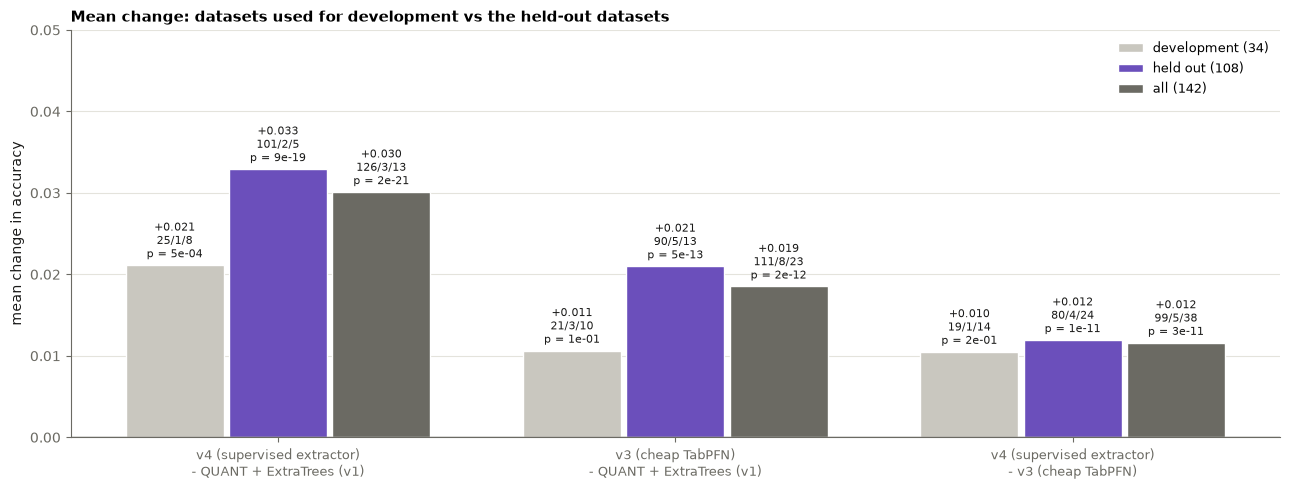

In [7]:
DEV = [d for d in DATASETS if d in dataset_list("dev34")]             # used to choose the settings
HELDOUT = [d for d in DATASETS if d in dataset_list("heldout108")]    # never used to choose anything
SUBSETS = {f"development ({len(DEV)})": DEV, f"held out ({len(HELDOUT)})": HELDOUT, f"all ({len(DATASETS)})": DATASETS}
SUBSET_COLORS = [GROUP_COLORS["development"], GROUP_COLORS["held out"], GROUP_COLORS["all"]]
PAIRS = [("v4", "v1"), ("v3", "v1"), ("v4", "v3")]           # from here on: v4 - v1 first

fig, ax = plt.subplots(figsize=(13, 5))
width = 0.26
for s, (subset, names) in enumerate(SUBSETS.items()):
    for p, (a, b) in enumerate(PAIRS):
        change = MEAN.loc[names, a] - MEAN.loc[names, b]
        better, equal, worse = wdl_counts(change)
        p_value = stats.wilcoxon(MEAN.loc[names, a], MEAN.loc[names, b]).pvalue
        x = p + (s - 1) * width                               # three bars side by side around each pair
        label = subset if p == 0 else None                    # name each subset once in the legend
        ax.bar(x, change.mean(), width * 0.95, color=SUBSET_COLORS[s], edgecolor="white", label=label)
        ax.annotate(f"{signed(change.mean())}\n{better}/{equal}/{worse}\np = {p_value:.0e}", (x, change.mean()),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=TEXT)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(range(len(PAIRS)), [f"{NAMES[a]}\n- {NAMES[b]}" for a, b in PAIRS], fontsize=9)
ax.set_ylim(0, 0.05)
ax.set_ylabel("mean change in accuracy")
ax.set_title("Mean change: datasets used for development vs the held-out datasets", loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

## 5b. The default split alone (resample 0)

Resample 0 is the archive's own split; resamples 1 to 29 are shuffled re-splits. Left: the mean change on each, with
better / equal / worse and the Wilcoxon p-value. Right: v4 on the default split against its mean over the shuffled
resamples; below the diagonal the default split is harder (the largest drops named).

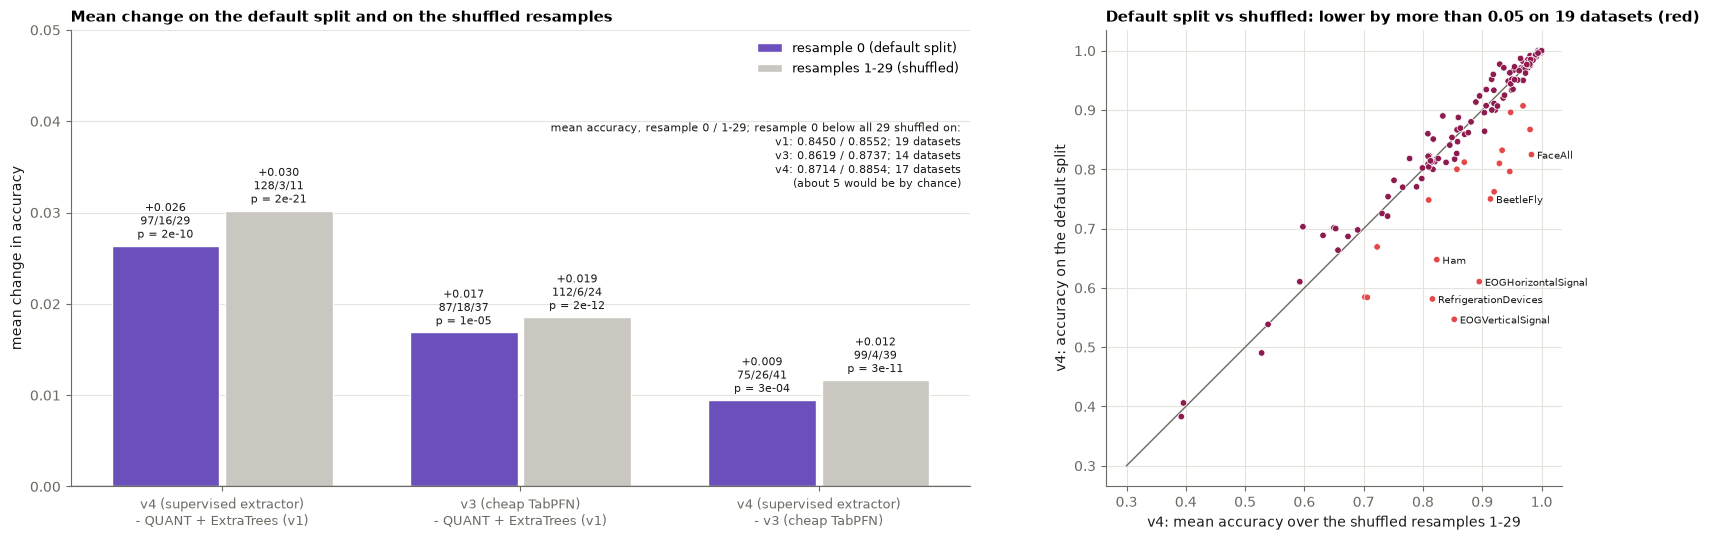

In [8]:
R0 = pd.DataFrame(index=DATASETS)                 # resample 0 (the default split), every dataset
SHUFFLED = pd.DataFrame(index=DATASETS)           # the mean of resamples 1-29
BELOW = {}                                        # datasets where resample 0 is below all 29 shuffled resamples
for n in NAMES:
    others = ACCURACY[n].drop(columns=0)          # resamples 1-29
    R0[n] = ACCURACY[n][0]
    SHUFFLED[n] = others.mean(axis=1)
    BELOW[n] = (R0[n] < others.min(axis=1) - 1e-12).sum()
SPLITS = {"resample 0 (default split)": R0, "resamples 1-29 (shuffled)": SHUFFLED}

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
width = 0.38
for s, (split, table) in enumerate(SPLITS.items()):
    for p, (a, b) in enumerate(PAIRS):
        change = table[a] - table[b]
        better, equal, worse = wdl_counts(change)
        p_value = stats.wilcoxon(table[a], table[b]).pvalue
        x = p + (s - 0.5) * width                             # two bars side by side around each pair
        color = GROUP_COLORS["held out"] if s == 0 else GROUP_COLORS["development"]
        label = split if p == 0 else None                     # name each split once in the legend
        ax.bar(x, change.mean(), width * 0.95, color=color, edgecolor="white", label=label)
        ax.annotate(f"{signed(change.mean())}\n{better}/{equal}/{worse}\np = {p_value:.0e}", (x, change.mean()),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=TEXT)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(range(len(PAIRS)), [f"{NAMES[a]}\n- {NAMES[b]}" for a, b in PAIRS], fontsize=9)
ax.set_ylim(0, 0.05)
ax.set_ylabel("mean change in accuracy")
ax.set_title("Mean change on the default split and on the shuffled resamples", loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper right")
lines = ["mean accuracy, resample 0 / 1-29; resample 0 below all 29 shuffled on:"]
for n in NAMES:
    lines.append(f"{n}: {R0[n].mean():.4f} / {SHUFFLED[n].mean():.4f}; {BELOW[n]} datasets")
lines.append(f"(about {len(DATASETS) / 30:.0f} would be by chance)")
ax.text(0.99, 0.80, "\n".join(lines), transform=ax.transAxes, ha="right", va="top", fontsize=8, color=TEXT)

ax = axes[1]
gap = R0["v4"] - SHUFFLED["v4"]
ax.plot([0.3, 1], [0.3, 1], color=MUTED, linewidth=1, zorder=1)
colors = [WORSE if g < -0.05 else RESULT_COLORS["v4"] for g in gap]    # red: more than 0.05 lower on the default split
ax.scatter(SHUFFLED["v4"], R0["v4"], s=22, color=colors, edgecolor="white", linewidth=0.5, zorder=3)
for name in gap.sort_values().index[:6]:                                 # the 6 largest drops, named
    ax.annotate(name, (SHUFFLED.loc[name, "v4"], R0.loc[name, "v4"]), xytext=(4, -3), textcoords="offset points",
                fontsize=7.5, color=TEXT)
ax.set_xlabel("v4: mean accuracy over the shuffled resamples 1-29")
ax.set_ylabel("v4: accuracy on the default split")
ax.set_title(f"Default split vs shuffled: lower by more than 0.05 on {(gap < -0.05).sum()} datasets (red)", loc="left")
ax.grid(True, axis="both")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 6. Against the published classifiers of the bake-off redux

The bake-off redux's published accuracies of 11 classifiers (the 112 UCR datasets, 30 resamples; downloaded, see
`experiments.md`). Second figure: the critical-difference diagram (mean ranks; a bar joins the results whose pairwise
Wilcoxon tests are not significant after Holm's correction over all pairs). The baselines of section 2b are added (light). QUANT is the published QUANT; our v1 (the same method) is left out
here, so that QUANT appears once.
Friedman's test first: only if the classifiers differ at all are the post-hoc comparisons justified.

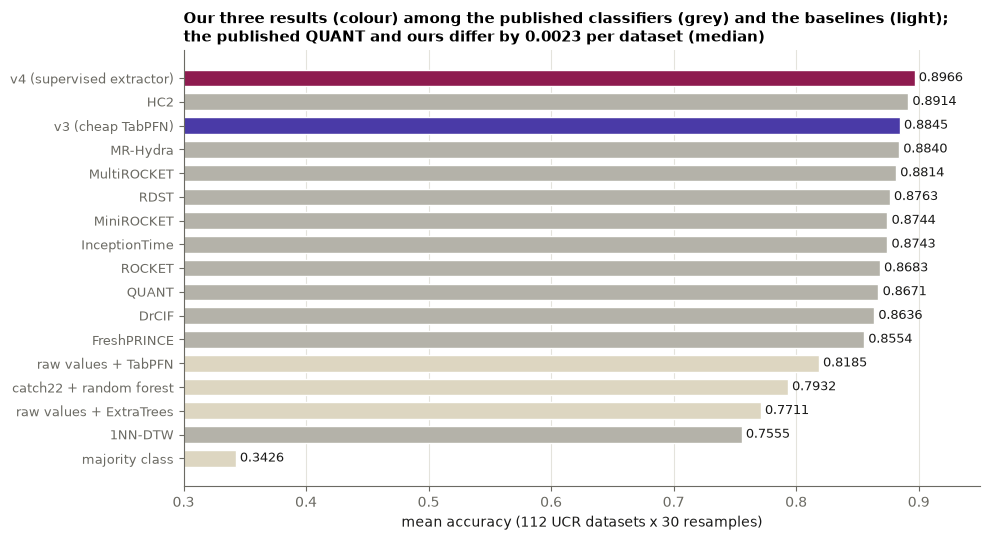

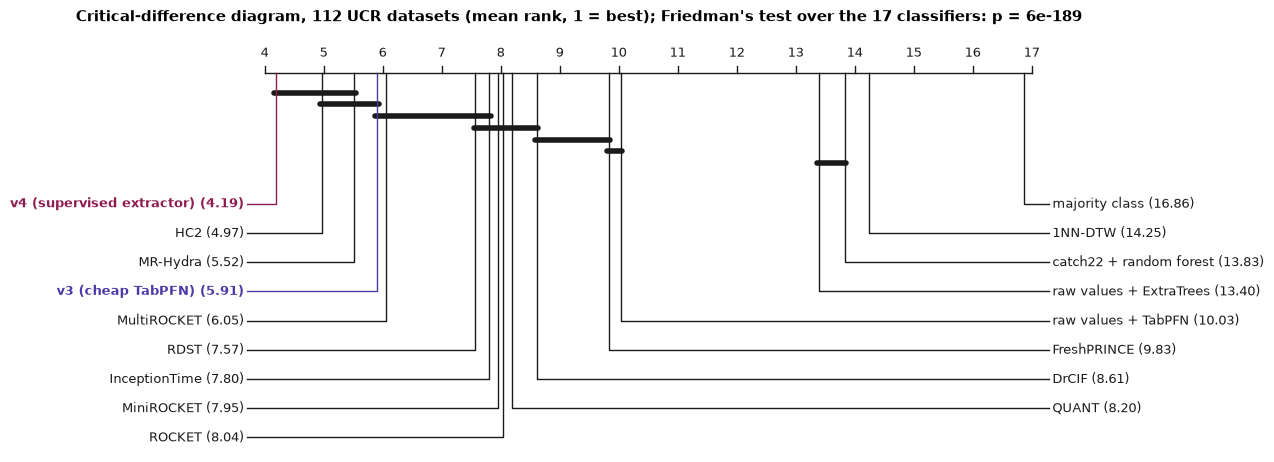

In [9]:
# the published accuracies as downloaded: one file per classifier, one row per dataset, one column per resample
REF_MEAN = pd.DataFrame()                                 # one column per classifier: its mean accuracy per dataset
for f in sorted((RESULTS_DIR / "bakeoff-redux").glob("*_accuracy.csv")):
    name = f.name.replace("_accuracy.csv", "")
    if name == "MR":
        name = "MultiROCKET"
    REF_MEAN[name] = pd.read_csv(f, index_col=0).mean(axis=1)
UCR112 = [d for d in DATASETS if d in REF_MEAN.index]
BENCH = REF_MEAN.loc[UCR112].copy()
for n in ["v3", "v4"]:                                   # v1 is QUANT itself: the published QUANT stands for it
    BENCH[NAMES[n]] = MEAN.loc[UCR112, n]
for name in BASE_MEAN:                                   # the baselines of section 2b
    BENCH[name] = BASE_MEAN.loc[UCR112, name]

columns = [BENCH[c] for c in BENCH]
friedman = stats.friedmanchisquare(*columns)             # *columns: each column is one argument
check = (BENCH["QUANT"] - MEAN.loc[UCR112, "v1"]).abs()          # the published QUANT against our v1

means = BENCH.mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(range(len(means)), means, 0.7, color=[color_of(n) for n in means.index], edgecolor="white")
ax.bar_label(bars, fmt="{:.4f}", padding=3, fontsize=9, color=TEXT)
ax.set_yticks(range(len(means)), means.index, fontsize=9)
ax.set_xlim(0.30, 0.95)
ax.set_xlabel("mean accuracy (112 UCR datasets x 30 resamples)")
ax.set_title("Our three results (colour) among the published classifiers (grey) and the baselines (light);\n"
             "the published QUANT and ours"
             f" differ by {check.median():.4f} per dataset (median)", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()


def cd_diagram(scores, highlight=(), alpha=0.05, title="", labels=None, size=None, fontsize=9, path=None):
    """Critical-difference diagram (as aeon's plot_critical_difference): mean ranks, and bars joining the classifiers
    whose pairwise Wilcoxon signed-rank tests are not significant after Holm's correction.
    labels: shorter names to show; size: (width, height) in inches; path: also save as path.pdf and path.png."""
    ranks = scores.rank(axis=1, ascending=False).mean().sort_values()     # rank per dataset, then the mean
    names, k = list(ranks.index), len(ranks)
    pairs = []                                           # every pair (i, j) with i < j
    p = []                                               # its Wilcoxon p-value
    for i in range(k):
        for j in range(i + 1, k):
            pairs.append((i, j))
            if (scores[names[i]] - scores[names[j]]).abs().max() < 1e-12:
                p.append(1.0)                            # identical results: no test possible
            else:
                p.append(stats.wilcoxon(scores[names[i]], scores[names[j]]).pvalue)
    same = np.ones((k, k), dtype=bool)                   # True: no significant difference
    for step, index in enumerate(np.argsort(p)):         # Holm: smallest p first, reject while p <= alpha / (tests left)
        if p[index] > alpha / (len(p) - step):
            break
        i, j = pairs[index]
        same[i, j] = same[j, i] = False
    cliques = []                                         # the longest runs of neighbours without a difference
    for i in range(k):
        j = i
        while j + 1 < k and same[i:j + 2, i:j + 2].all():   # grow while all of i..j+1 are alike
            j += 1
        inside = any(a <= i and j <= b for a, b in cliques)   # already part of a longer bar
        if j > i and not inside:
            cliques.append((i, j))
    lo, hi = np.floor(ranks.min()), np.ceil(ranks.max())
    half = (k + 1) // 2
    if size is None:
        size = (13, 1.6 + 0.32 * half)
    fig, ax = plt.subplots(figsize=size)
    ax.plot([lo, hi], [0, 0], color=TEXT, linewidth=1)
    for r in np.arange(lo, hi + 1):
        ax.plot([r, r], [0, 0.08], color=TEXT, linewidth=1)
        ax.text(r, 0.14, f"{r:.0f}", ha="center", va="bottom", fontsize=fontsize, color=TEXT)
    for c, (i, j) in enumerate(cliques):
        y = -0.2 - 0.12 * c
        ax.plot([ranks.iloc[i] - 0.03, ranks.iloc[j] + 0.03], [y, y], color=TEXT, linewidth=4, solid_capstyle="round")
    top = -0.2 - 0.12 * len(cliques)                     # the names start below the clique bars
    for n, (name, r) in enumerate(ranks.items()):        # the better half on the left, the rest on the right
        left = n < half
        y = top - 0.3 * ((n if left else k - 1 - n) + 1)
        edge = lo - 0.3 if left else hi + 0.3
        color, weight = (color_of(name), "bold") if name in highlight else (TEXT, "normal")     # ours in their colours
        ax.plot([r, r, edge], [0, y, y], color=color, linewidth=1)
        label = labels.get(name, name) if labels else name
        ax.text(edge + (-0.05 if left else 0.05), y, f"{label} ({r:.2f})", ha="right" if left else "left",
                va="center", fontsize=fontsize, color=color, fontweight=weight)
    ax.set_xlim(lo - 3.2, hi + 3.2)
    ax.set_ylim(top - 0.3 * (half + 0.5), 0.45)
    ax.axis("off")
    if title:
        ax.set_title(title, loc="left")
    fig.tight_layout(pad=0.2)
    if path:
        fig.savefig(f"{path}.pdf", bbox_inches="tight")
        fig.savefig(f"{path}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return ranks, cliques


ranks, cliques = cd_diagram(BENCH, highlight=OURS,
                            title=f"Critical-difference diagram, 112 UCR datasets (mean rank, 1 = best); Friedman's test "
                                  f"over the {BENCH.shape[1]} classifiers: p = {friedman.pvalue:.0e}")

## 6b. The figure for the report

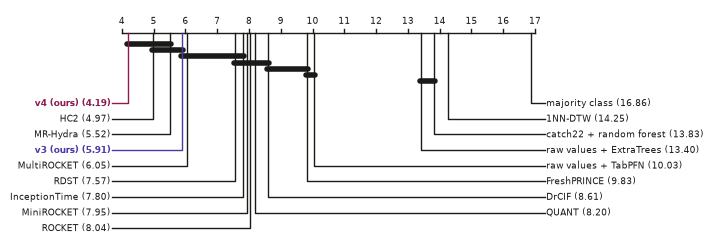

In [ ]:
FIGURES_DIR = REPO / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
REPORT_FONT = {"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5}
SHORT = {NAMES["v4"]: "v4 (ours)", NAMES["v3"]: "v3 (ours)", NAMES["v1"]: "QUANT + ExtraTrees, v1 (ours)",
         "raw values + ExtraTrees": "raw values + ExtraTrees", "catch22 + random forest": "catch22 + random forest",
         "majority class": "majority class", "raw values + TabPFN": "raw values + TabPFN"}

with plt.rc_context(REPORT_FONT):
    cd_diagram(BENCH, highlight=OURS, labels=SHORT, size=(7.16, 2.3), fontsize=6.5,
               path=FIGURES_DIR / "fig_cd_diagram")


## 6c. v4 against every other classifier (one row of a multiple comparison matrix)

Per comparison (112 datasets): the mean change, better / equal / worse,
the two-sided Wilcoxon p-value and Holm's correction over this family of tests. The critical-difference diagram above
corrects over all pairs of classifiers instead (many more tests), so it is stricter: a difference can be significant here
and not there.

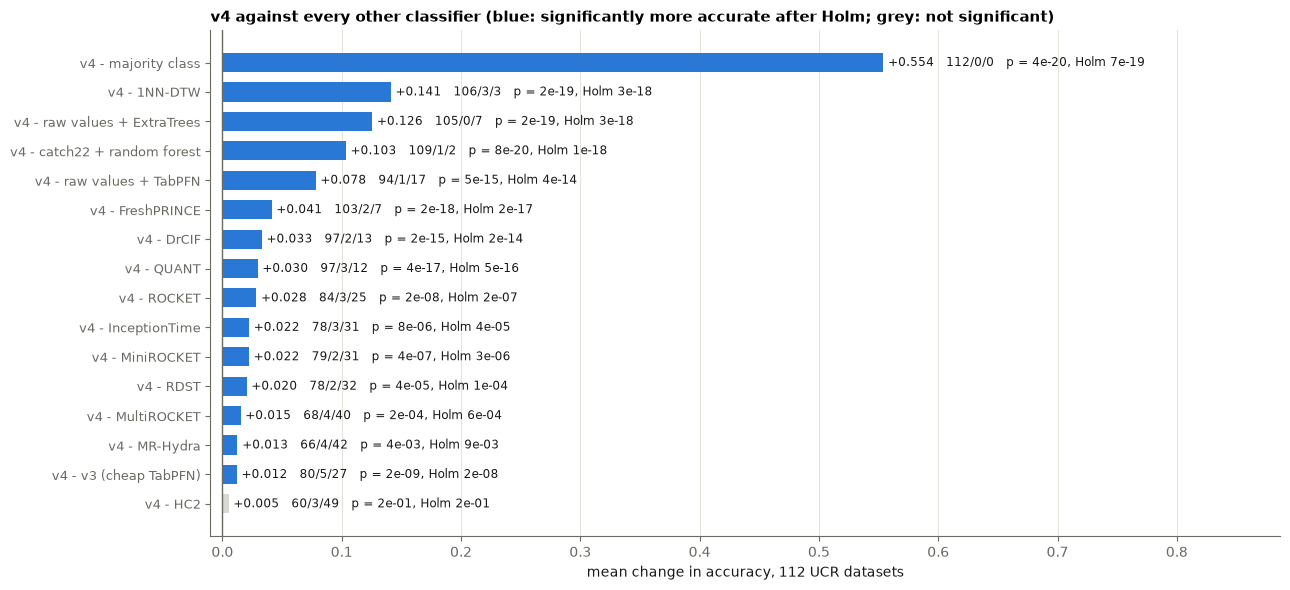

In [11]:
V4 = NAMES["v4"]
mcm = []
for other in BENCH.columns.drop(V4):
    change = BENCH[V4] - BENCH[other]
    better, equal, worse = wdl_counts(change)
    mcm.append({"other": other, "change": change.mean(), "wdl": f"{better}/{equal}/{worse}",
                "p": stats.wilcoxon(BENCH[V4], BENCH[other]).pvalue})
mcm = pd.DataFrame(mcm).set_index("other").sort_values("change")
mcm["holm"] = holm(mcm["p"])

fig, ax = plt.subplots(figsize=(13, 6))
y = np.arange(len(mcm))
colors = []
for change, q in zip(mcm["change"], mcm["holm"]):            # zip: walk the two columns together
    if q >= 0.05:
        colors.append(EQUAL)                                   # grey: not significant after Holm
    elif change > 0:
        colors.append(BETTER)
    else:
        colors.append(WORSE)
ax.barh(y, mcm["change"], 0.65, color=colors)
for yy, (name, row) in zip(y, mcm.iterrows()):
    ax.text(row["change"] + 0.004, yy, f"{signed(row['change'])}   {row['wdl']}   p = {row['p']:.0e}, Holm {row['holm']:.0e}",
            va="center", fontsize=8.5, color=TEXT)
ax.set_yticks(y, [f"v4 - {n}" for n in mcm.index], fontsize=9)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlim(min(0, mcm["change"].min()) - 0.01, mcm["change"].max() * 1.6)
ax.set_xlabel("mean change in accuracy, 112 UCR datasets")
ax.set_title("v4 against every other classifier (blue: significantly more accurate after Holm; grey: not significant)",
             loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## 6d. Accuracy at what cost

Mean rank (from the critical-difference diagram) against the hours one resample of the 112 UCR datasets takes. The
published classifiers: their own fit + predict times from the bake-off redux (one CPU core per run, their cluster;
milliseconds in the downloaded files). Ours: measured on our laptop. The two machines are calibrated by QUANT itself:
the published QUANT needs the hours in the figure's title, our run of the same code on one core of our laptop slightly
less, so our hours are multiplied by that factor (each point is labelled with its hours per resample). Only one-core
runs are compared, as the published times are one-core times: QUANT + ExtraTrees (v1) and v4 without the GPU
(resample 0; v3 has no one-core run). The time axis is logarithmic, because the times range from minutes to weeks.

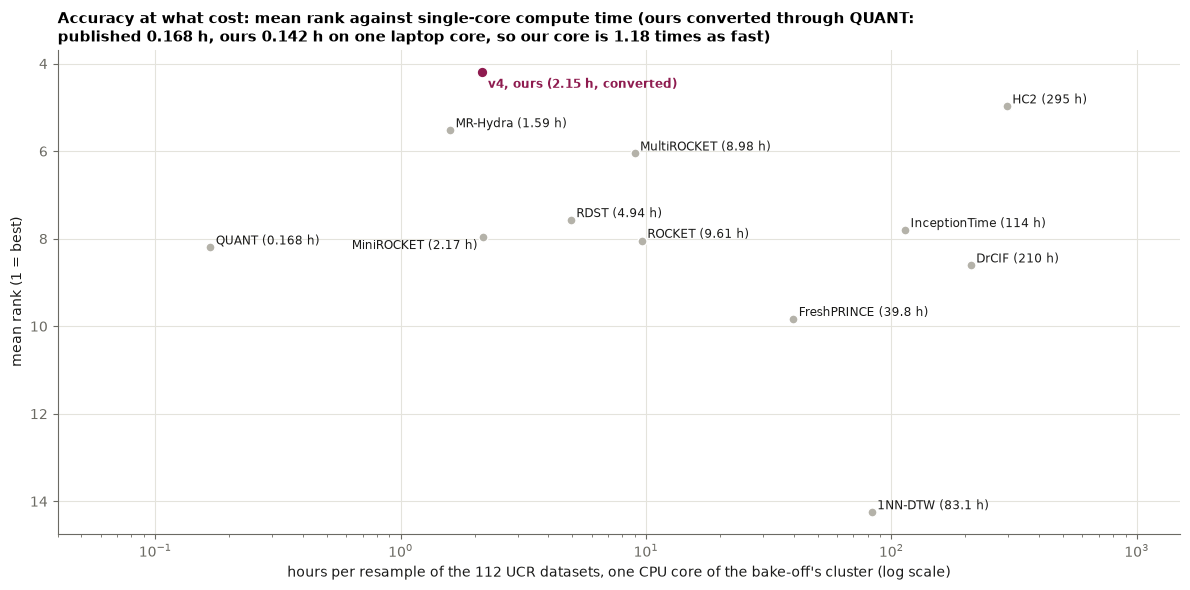

In [12]:
# the published times: fit + predict per dataset and resample, in milliseconds, one core of their cluster
REF_HOURS = {}
for f in sorted((RESULTS_DIR / "bakeoff-redux").glob("*_fittime.csv")):
    name = f.name.replace("_fittime.csv", "")
    fit = pd.read_csv(f, index_col=0)
    predict = pd.read_csv(f.with_name(f"{name}_predicttime.csv"), index_col=0)
    hours_per_resample = (fit + predict).loc[UCR112].sum().mean() / 1000 / 3600      # sum over datasets, mean over resamples
    if name == "MR":
        name = "MultiROCKET"
    REF_HOURS[name] = hours_per_resample


def our_hours(runs):
    """Our hours per resample on the 112 UCR datasets."""
    runs = runs[runs["dataset"].isin(UCR112)]
    return runs["total_time"].sum() / runs["resample"].nunique() / 3600


# ours: the one-core runs only, as the published times (v3 has no one-core run)
V1_ONE = NAMES["v1"] + ", one core"
OUR_HOURS = {V1_ONE: our_hours(v1_runs)}
ONECORE = RESULTS_DIR / "v4_tabpfn-e2f200_ucr142-r0_onecore-cpu.csv"     # v4 on one core without the GPU, resample 0
one = load_runs(ONECORE)
one = one[(one["status"] == "ok") & one["dataset"].isin(UCR112)]
assert one["dataset"].nunique() == len(UCR112)
OUR_HOURS[NAMES["v4"] + ", one core, no GPU"] = one["total_time"].sum() / 3600
factor = REF_HOURS["QUANT"] / OUR_HOURS[V1_ONE]          # how much faster our laptop core is
CONVERTED = {}                                                       # our hours on one core of their cluster
for name, h in OUR_HOURS.items():
    CONVERTED[name] = h * factor


# where a label goes (offset in points, horizontal alignment), so that nearby labels do not overlap
LABEL_PLACE = {"MiniROCKET": (-4, -9, "right")}


def cost_plot(ax, fontsize, show_hours):
    """Mean rank against hours per resample on one core of their cluster: published (grey) and ours (colour)."""
    for name, h in REF_HOURS.items():
        ax.scatter(h, ranks[name], s=fontsize * 5, color=OTHERS, edgecolor="white", zorder=3)
        text = f"{name} ({h:.3g} h)" if show_hours else name
        dx, dy, ha = LABEL_PLACE.get(name, (4, 2, "left"))
        ax.annotate(text, (h, ranks[name]), xytext=(dx, dy), textcoords="offset points", fontsize=fontsize, color=TEXT,
                    ha=ha)
    for name, h in CONVERTED.items():
        if name == V1_ONE:
            continue                                                      # v1 is QUANT: only used to convert
        result = name.split(", ")[0]                                      # e.g. "v4 (supervised extractor)"
        code = CODE_OF[result]
        text = f"{code}, ours" + (f" ({h:.3g} h, converted)" if show_hours else "")
        dx, dy, ha = LABEL_PLACE.get(code, (4, -fontsize - 3, "left"))
        ax.scatter(h, ranks[result], s=fontsize * 7, color=color_of(result), edgecolor="white", zorder=4)
        ax.annotate(text, (h, ranks[result]), xytext=(dx, dy), textcoords="offset points", fontsize=fontsize,
                    color=color_of(result), fontweight="bold", ha=ha)
    ax.set_xscale("log")
    ax.invert_yaxis()                                                     # rank 1 at the top
    ax.set_ylabel("mean rank (1 = best)")
    ax.grid(True, axis="both")


fig, ax = plt.subplots(figsize=(12, 6))
cost_plot(ax, 8.5, show_hours=True)
ax.set_xlim(0.04, 1500)
ax.set_xlabel("hours per resample of the 112 UCR datasets, one CPU core of the bake-off's cluster (log scale)")
ax.set_title("Accuracy at what cost: mean rank against single-core compute time (ours converted through QUANT:\n"
             f"published {REF_HOURS['QUANT']:.3f} h, ours {OUR_HOURS[V1_ONE]:.3f} h on one laptop core, "
             f"so our core is {factor:.2f} times as fast)", loc="left")
fig.tight_layout()
plt.show()


## 6e. The other figures for the report

At the width of one IEEE column (3.5 inches): v4 against QUANT + ExtraTrees on every dataset (section 3), and the mean
rank against single-core compute time (section 6d). Saved to `figures/fig_v4_vs_v1` and `figures/fig_cost` (`.pdf`
for LaTeX and `.png`).

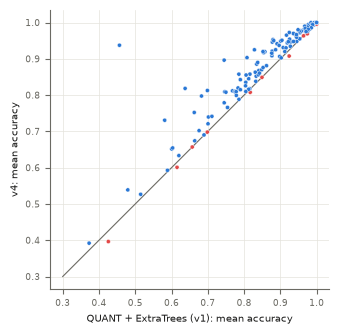

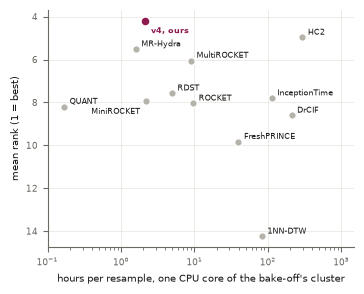

In [13]:
# (2) v4 against QUANT + ExtraTrees, per dataset (142 datasets)
change = MEAN["v4"] - MEAN["v1"]
with plt.rc_context(REPORT_FONT):
    fig, ax = plt.subplots(figsize=(3.5, 3.2))
    ax.plot([0.3, 1.0], [0.3, 1.0], color=MUTED, linewidth=0.8, zorder=1)          # the diagonal: equal accuracy
    ax.scatter(MEAN["v1"], MEAN["v4"], s=9, c=[change_color(x) for x in change], edgecolor="white", linewidth=0.3,
               zorder=3)
    ax.set_xlabel("QUANT + ExtraTrees (v1): mean accuracy")
    ax.set_ylabel("v4: mean accuracy")
    ax.set_aspect("equal")
    ax.grid(True, axis="both", linewidth=0.5)
    fig.tight_layout(pad=0.3)
    fig.savefig(FIGURES_DIR / "fig_v4_vs_v1.pdf", bbox_inches="tight")
    fig.savefig(FIGURES_DIR / "fig_v4_vs_v1.png", dpi=300, bbox_inches="tight")
    plt.show()

# (3) mean rank against single-core compute time (112 UCR datasets)
with plt.rc_context(REPORT_FONT):
    fig, ax = plt.subplots(figsize=(3.5, 2.8))
    cost_plot(ax, 6, show_hours=False)
    ax.set_xlabel("hours per resample, one CPU core of the bake-off's cluster")
    ax.set_xlim(0.1, 1500)
    ax.grid(True, axis="both", linewidth=0.5)
    fig.tight_layout(pad=0.3)
    fig.savefig(FIGURES_DIR / "fig_cost.pdf", bbox_inches="tight")
    fig.savefig(FIGURES_DIR / "fig_cost.png", dpi=300, bbox_inches="tight")
    plt.show()


## 7. How sure are the differences? Confidence intervals and the spread over resamples

Left: 95% bootstrap intervals of the mean changes (the datasets resampled 10,000 times). Right: the standard
deviation of every dataset over its 30 resamples; below the diagonal v4 varies less.

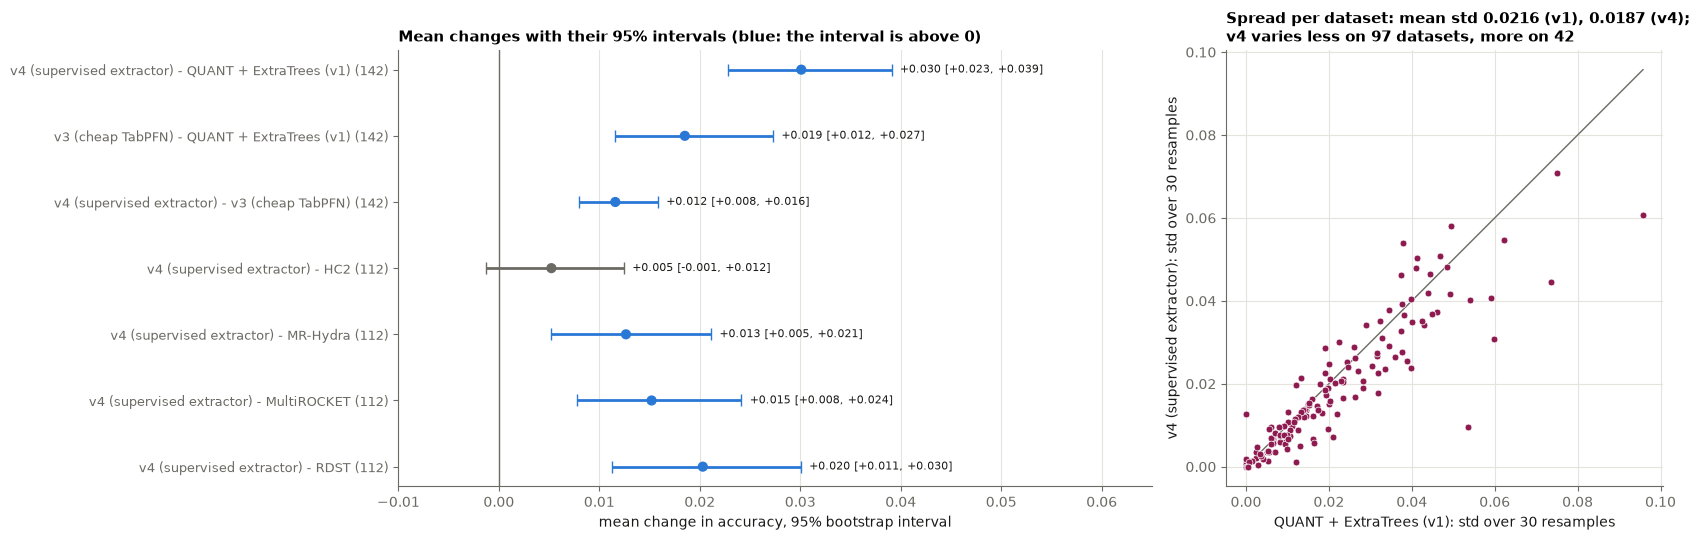

In [14]:
rng = np.random.default_rng(0)


def bootstrap_ci(change, n=10_000):
    """Mean change and its 95% bootstrap interval (the datasets resampled with replacement)."""
    change = np.asarray(change)
    picks = rng.integers(0, len(change), (n, len(change)))     # n rows of random dataset numbers (with repeats)
    means = change[picks].mean(axis=1)                         # the mean change of every row
    low, high = np.percentile(means, [2.5, 97.5])
    return change.mean(), low, high


INTERVALS = {f"{NAMES['v4']} - {NAMES['v1']} (142)": MEAN["v4"] - MEAN["v1"],
             f"{NAMES['v3']} - {NAMES['v1']} (142)": MEAN["v3"] - MEAN["v1"],
             f"{NAMES['v4']} - {NAMES['v3']} (142)": MEAN["v4"] - MEAN["v3"]}
for other in ["HC2", "MR-Hydra", "MultiROCKET", "RDST"]:
    INTERVALS[f"{NAMES['v4']} - {other} (112)"] = BENCH[NAMES["v4"]] - BENCH[other]
ci = pd.DataFrame([bootstrap_ci(change) for change in INTERVALS.values()], index=list(INTERVALS),
                  columns=["mean", "low", "high"])

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
y = np.arange(len(ci))[::-1]
colors = []
for _, row in ci.iterrows():
    if row["low"] > 0:
        colors.append(BETTER)                                  # the whole interval above 0
    elif row["high"] < 0:
        colors.append(WORSE)
    else:
        colors.append(MUTED)
for yy, color, (_, row) in zip(y, colors, ci.iterrows()):     # one interval at a time (one colour each)
    ax.errorbar(row["mean"], yy, xerr=[[row["mean"] - row["low"]], [row["high"] - row["mean"]]], fmt="none",
                ecolor=color, elinewidth=2, capsize=4)
ax.scatter(ci["mean"], y, color=colors, s=40, zorder=3)
for yy, (_, row) in zip(y, ci.iterrows()):
    ax.annotate(f"{signed(row['mean'])} [{signed(row['low'])}, {signed(row['high'])}]", (row["high"], yy),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=TEXT)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, ci.index, fontsize=9)
ax.set_xlim(-0.01, 0.065)
ax.set_xlabel("mean change in accuracy, 95% bootstrap interval")
ax.set_title("Mean changes with their 95% intervals (blue: the interval is above 0)", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")

ax = axes[1]
spread = pd.DataFrame({name: table.std(axis=1) for name, table in ACCURACY.items()})
less, _, more = wdl_counts(spread["v1"] - spread["v4"])
ax.plot([0, spread.max().max()], [0, spread.max().max()], color=MUTED, linewidth=1, zorder=1)
ax.scatter(spread["v1"], spread["v4"], s=24, color=RESULT_COLORS["v4"], edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xlabel(f"{NAMES['v1']}: std over 30 resamples")
ax.set_ylabel(f"{NAMES['v4']}: std over 30 resamples")
ax.set_title(f"Spread per dataset: mean std {spread['v1'].mean():.4f} (v1), {spread['v4'].mean():.4f} (v4);\n"
             f"v4 varies less on {less} datasets, more on {more}", loc="left")
ax.grid(True, axis="both")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 7b. Seeds

The full runs use one seed (0) for every resample, so the spread over resamples mixes the split and the seed. Resample
0 again with seeds 0 to 4 (ExtraTrees' randomness; v4's template choice, ExtraTrees ranking and TabPFN's passes):
left, the mean accuracy of each seed; right, every dataset's standard deviation over the 5 seeds against its standard
deviation over the 30 resamples.

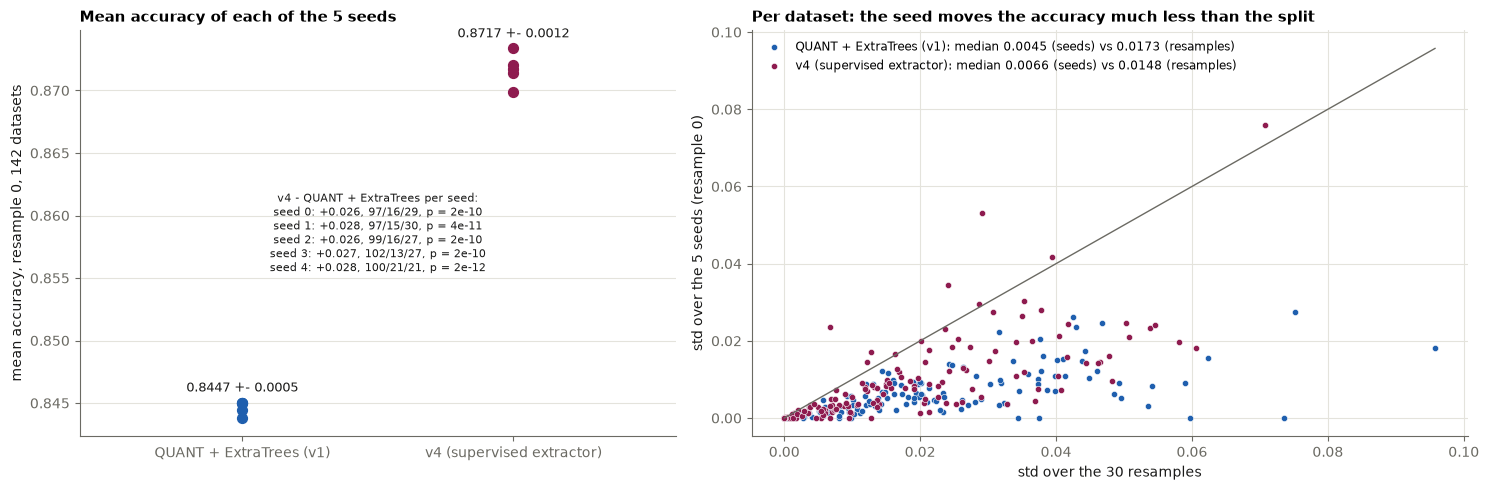

In [15]:
SEED_ACC = {}                                            # one row per dataset, one column per seed
for name, runs in seed_runs.items():
    SEED_ACC[name] = runs[runs["status"] == "ok"].pivot(index="dataset", columns="seed", values="accuracy").loc[DATASETS]
    assert (SEED_ACC[name][0] == ACCURACY[name][0]).all()      # seed 0 repeats resample 0 of the full run exactly
gains = SEED_ACC["v4"] - SEED_ACC["v1"]
seed_lines = ["v4 - QUANT + ExtraTrees per seed:"]
for seed in gains:
    better, equal, worse = wdl_counts(gains[seed])
    p_value = stats.wilcoxon(SEED_ACC["v4"][seed], SEED_ACC["v1"][seed]).pvalue
    seed_lines.append(f"seed {seed}: {signed(gains[seed].mean())}, {better}/{equal}/{worse}, p = {p_value:.0e}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
for x, name in enumerate(SEED_ACC):
    means = SEED_ACC[name].mean()
    ax.scatter(np.full(len(means), x), means, s=50, color=RESULT_COLORS[name], zorder=3)
    ax.annotate(f"{means.mean():.4f} +- {means.std():.4f}", (x, means.max()), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9, color=TEXT)
ax.set_xticks(range(len(SEED_ACC)), [NAMES[n] for n in SEED_ACC])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("mean accuracy, resample 0, 142 datasets")
ax.set_title("Mean accuracy of each of the 5 seeds", loc="left")
ax.text(0.5, 0.5, "\n".join(seed_lines), transform=ax.transAxes, ha="center", va="center", fontsize=8, color=TEXT)
ax = axes[1]
for name in SEED_ACC:
    seed_sd, resample_sd = SEED_ACC[name].std(axis=1), ACCURACY[name].std(axis=1)
    ax.scatter(resample_sd, seed_sd, s=20, color=RESULT_COLORS[name], edgecolor="white", linewidth=0.4,
               label=f"{NAMES[name]}: median {seed_sd.median():.4f} (seeds) vs {resample_sd.median():.4f} (resamples)")
top = max(ACCURACY["v1"].std(axis=1).max(), ACCURACY["v4"].std(axis=1).max())
ax.plot([0, top], [0, top], color=MUTED, linewidth=1, zorder=1)
ax.set_xlabel("std over the 30 resamples")
ax.set_ylabel("std over the 5 seeds (resample 0)")
ax.set_title("Per dataset: the seed moves the accuracy much less than the split", loc="left")
ax.legend(frameon=False, fontsize=8.5)
ax.grid(True, axis="both")
fig.tight_layout()
plt.show()

## 8. Beyond accuracy: balanced accuracy, AUROC and log loss

From the predicted probabilities. The log loss (lower is better) rewards probabilities that can be trusted;
ExtraTrees' vote shares are often 0 or 1 (clipped at 1e-15).

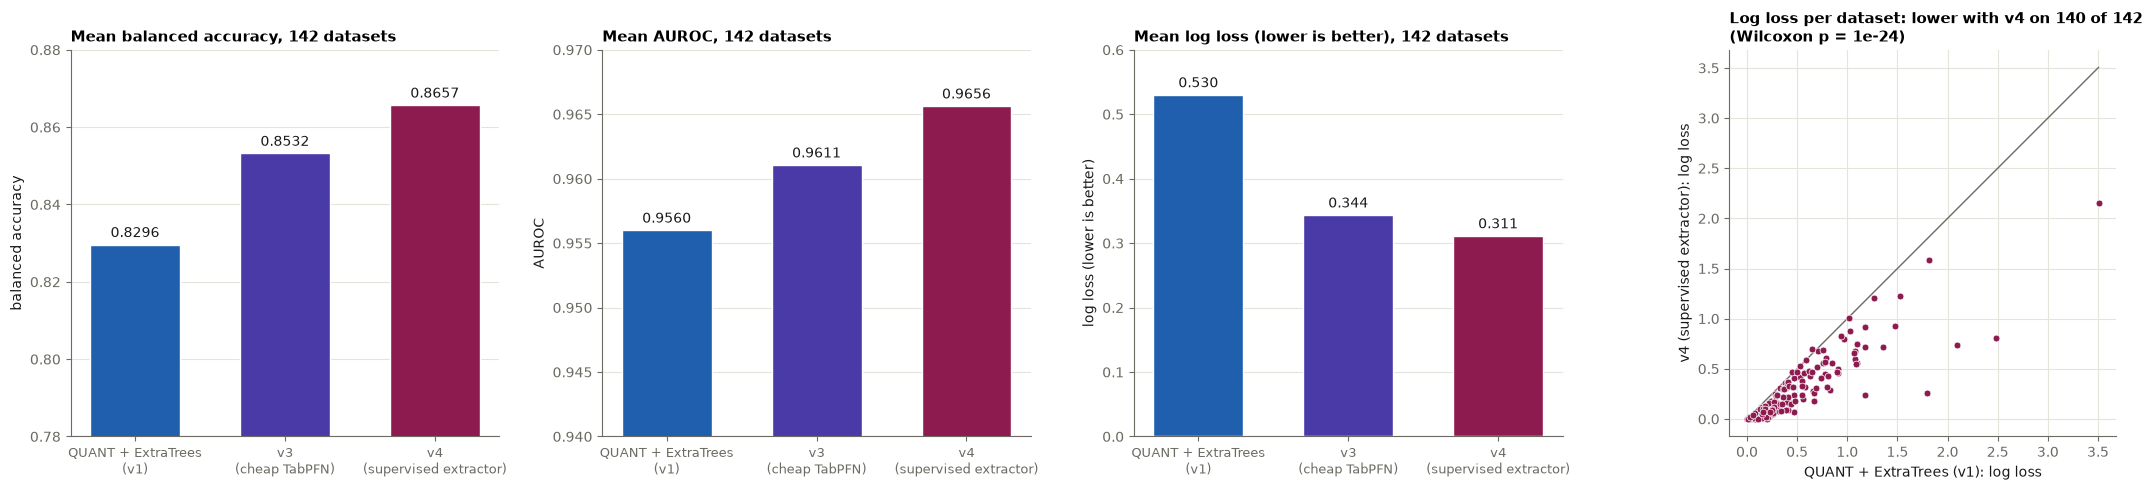

In [16]:
METRICS = {"balanced_accuracy": "balanced accuracy", "auroc": "AUROC", "log_loss": "log loss (lower is better)"}
PER_DATASET = {}                                         # the mean of each metric per dataset
for name, runs in {"v1": v1_runs, "v3": v3_runs, "v4": v4_runs}.items():
    PER_DATASET[name] = runs.groupby("dataset")[list(METRICS)].mean().loc[DATASETS]
change = PER_DATASET["v4"]["log_loss"] - PER_DATASET["v1"]["log_loss"]
better, equal, worse = wdl_counts(-change)               # lower log loss is better: count -change
p_value = stats.wilcoxon(PER_DATASET["v4"]["log_loss"], PER_DATASET["v1"]["log_loss"]).pvalue

fig, axes = plt.subplots(1, 4, figsize=(22, 5), gridspec_kw={"width_ratios": [1, 1, 1, 1.2]})
for ax, metric, ylim, fmt in [(axes[0], "balanced_accuracy", (0.78, 0.88), "{:.4f}"),
                              (axes[1], "auroc", (0.94, 0.97), "{:.4f}"),
                              (axes[2], "log_loss", (0, 0.6), "{:.3f}")]:
    values = [PER_DATASET[n][metric].mean() for n in NAMES]
    bars = ax.bar(range(len(NAMES)), values, 0.6, color=[RESULT_COLORS[n] for n in NAMES], edgecolor="white")
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=10, color=TEXT)
    ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_ylabel(METRICS[metric])
    ax.set_title(f"Mean {METRICS[metric]}, 142 datasets", loc="left")
ax = axes[3]
top = max(PER_DATASET["v1"]["log_loss"].max(), PER_DATASET["v4"]["log_loss"].max())
ax.plot([0, top], [0, top], color=MUTED, linewidth=1, zorder=1)
ax.scatter(PER_DATASET["v1"]["log_loss"], PER_DATASET["v4"]["log_loss"], s=24, color=RESULT_COLORS["v4"],
           edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xlabel(f"{NAMES['v1']}: log loss")
ax.set_ylabel(f"{NAMES['v4']}: log loss")
ax.set_title(f"Log loss per dataset: lower with v4 on {better} of {len(DATASETS)}\n(Wilcoxon p = {p_value:.0e})",
             loc="left")
ax.grid(True, axis="both")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 8b. Every metric on the default split

Resample 0, seed 0, all 142 datasets: accuracy, balanced accuracy (the mean recall over the classes), macro F1 (every
class counts the same), AUROC (one class against the rest, weighted by class size), log loss and the Brier score (both
lower is better; they score the probabilities). The baselines as well. The Wilcoxon test of v4 against QUANT +
ExtraTrees for every metric is in each panel's title (better / equal / worse datasets and p).

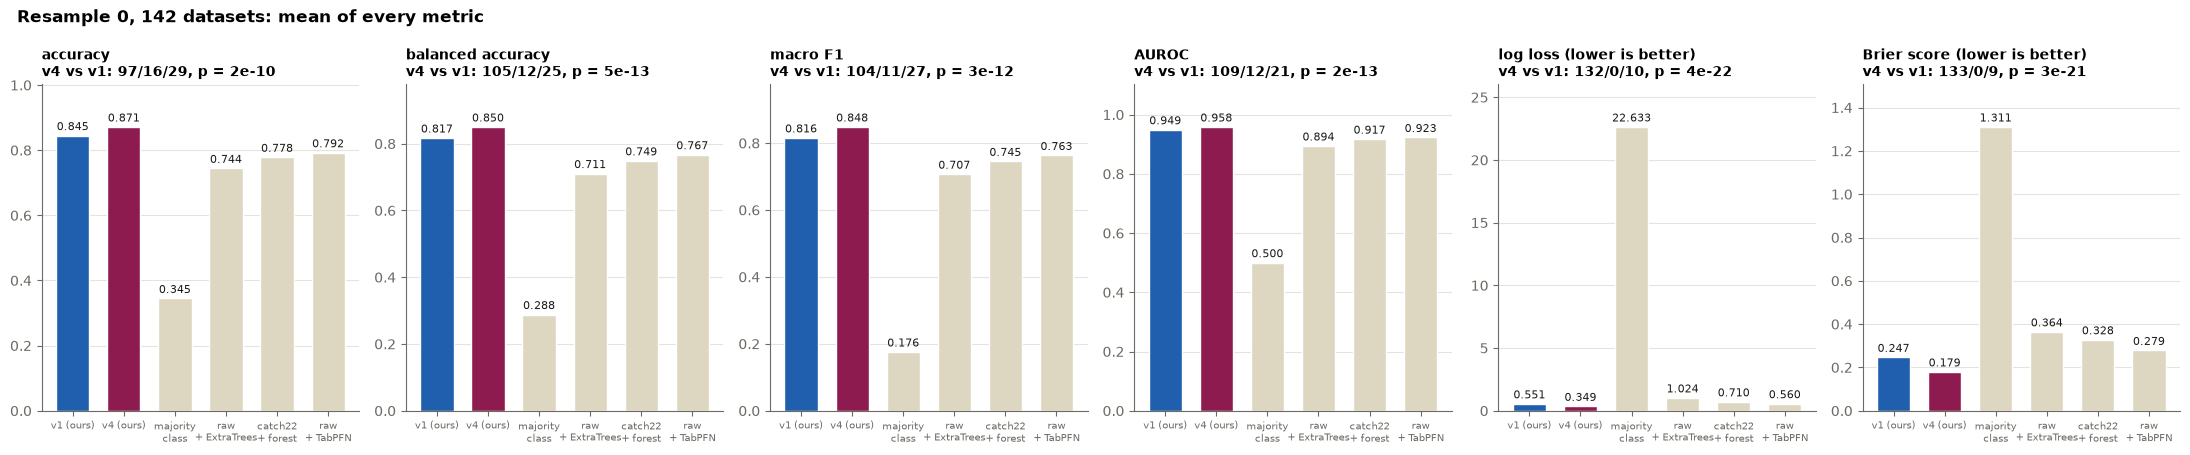

In [17]:
R0_METRICS = {"accuracy": "accuracy", "balanced_accuracy": "balanced accuracy", "f1_macro": "macro F1", "auroc": "AUROC",
              "log_loss": "log loss (lower is better)", "brier": "Brier score (lower is better)"}
R0_RESULTS = {NAMES["v1"]: seed0["v1"], NAMES["v4"]: seed0["v4"]}     # one row per dataset, resample 0
for key, label in BASELINE_NAMES.items():
    rows = base_runs[(base_runs["classifier"] == key) & (base_runs["resample"] == 0)]
    R0_RESULTS[label] = rows.set_index("dataset").loc[DATASETS]

TICKS = {NAMES["v1"]: "v1 (ours)", NAMES["v4"]: "v4 (ours)", "majority class": "majority\nclass",
         "raw values + ExtraTrees": "raw\n+ ExtraTrees", "catch22 + random forest": "catch22\n+ forest",
         "raw values + TabPFN": "raw\n+ TabPFN"}                   # short names under the bars
fig, axes = plt.subplots(1, len(R0_METRICS), figsize=(22, 4.6))
for ax, (metric, label) in zip(axes, R0_METRICS.items()):
    values = pd.Series({name: runs[metric].mean() for name, runs in R0_RESULTS.items()})
    bars = ax.bar(range(len(values)), values, 0.65, color=[color_of(n) for n in values.index], edgecolor="white")
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=8, color=TEXT)
    ax.set_xticks(range(len(values)), [TICKS[n] for n in values.index], fontsize=7)
    a, b = seed0["v4"][metric], seed0["v1"][metric]
    if metric in ("log_loss", "brier"):
        better, equal, worse = wdl_counts(b - a)             # lower is better
    else:
        better, equal, worse = wdl_counts(a - b)
    ax.set_title(f"{label}\nv4 vs v1: {better}/{equal}/{worse}, p = {stats.wilcoxon(a, b).pvalue:.0e}", loc="left",
                 fontsize=10)
    ax.set_ylim(0, values.max() * 1.15)
fig.suptitle("Resample 0, 142 datasets: mean of every metric", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

## 8c. Confusion matrices

Resample 0, seed 0, from the saved predictions: QUANT + ExtraTrees (left) and v4 (right) on three representative
datasets. The predictions were saved for all 142 datasets (the seed runs, `experiments.md`); of the datasets with at
most five classes these three are where v4 gains most (ChlorineConcentration), where it loses most (Ham) and the most
imbalanced test set (ECG5000). Only their six files are in the repository. Rows: the true class,
columns: the predicted class, each row as a share of its class (the counts written in the cells).

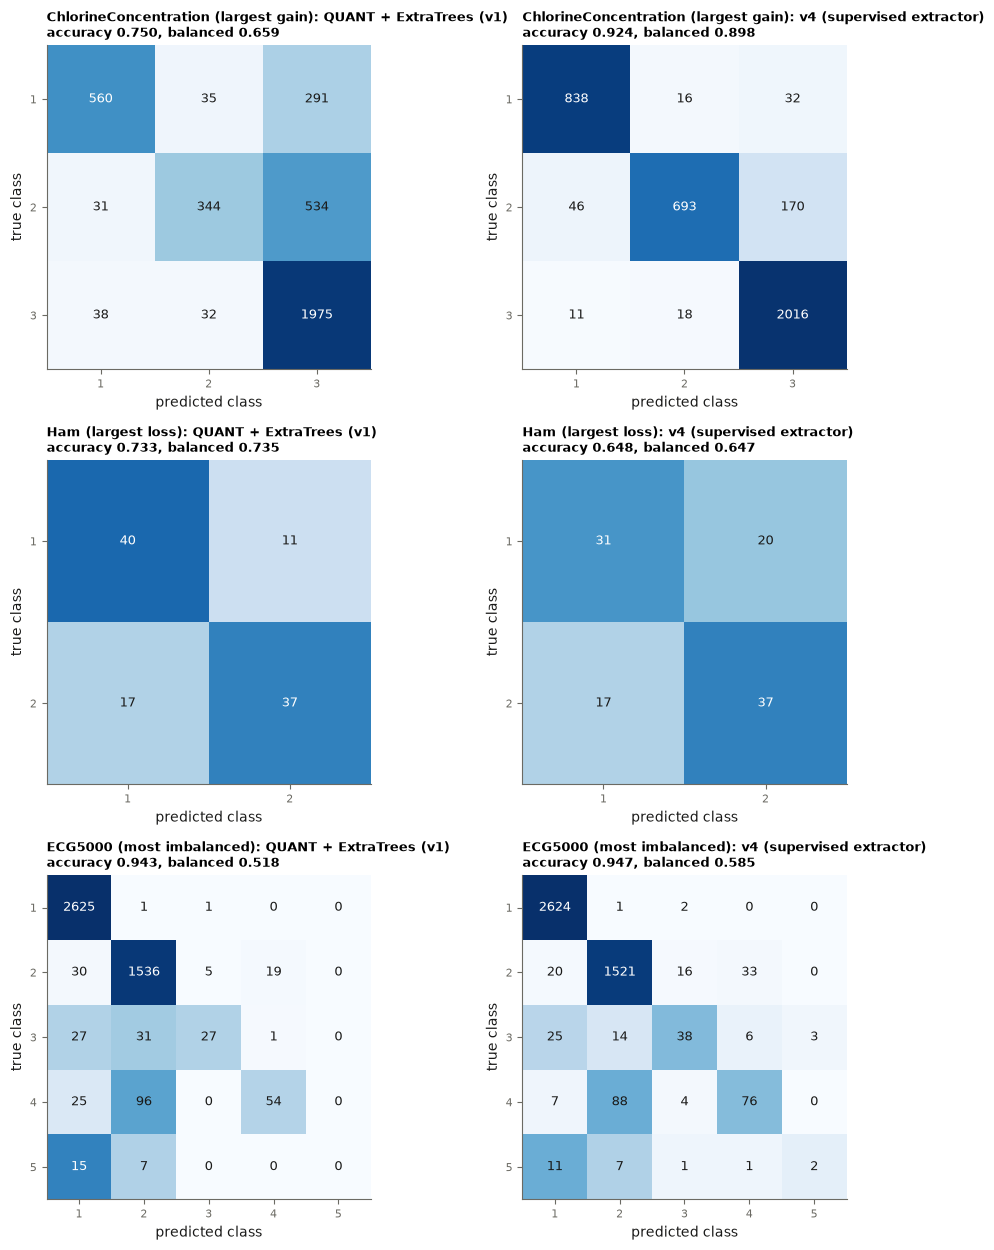

In [18]:
PREDICTIONS = {"v1": RESULTS_DIR / "v1-seeds_extratrees_ucr142-r0_allcores-cpu_predictions",
               "v4": RESULTS_DIR / "v4-seeds_tabpfn-e2f200_ucr142-r0_allcores-gpu_predictions"}
FILE_NAMES = {"v1": "extratrees", "v4": "tabpfn"}


def predictions(name, dataset):
    """(true classes, predicted classes, class names) of resample 0, seed 0."""
    z = np.load(PREDICTIONS[name] / f"{dataset}_0_{FILE_NAMES[name]}_s0.npz")
    return z["y_test"], z["proba"].argmax(1), z["classes"]      # predicted = the class with the highest probability


# chosen from the saved predictions of all 142 datasets (at most five classes): where v4 gains most, where it loses
# most, and the most imbalanced test set (largest / smallest class)
CHOSEN = {"largest gain": "ChlorineConcentration", "largest loss": "Ham", "most imbalanced": "ECG5000"}

fig, axes = plt.subplots(len(CHOSEN), 2, figsize=(10, 4.2 * len(CHOSEN)))
for row, (why, dataset) in enumerate(CHOSEN.items()):
    for col, name in enumerate(["v1", "v4"]):
        y, predicted, labels = predictions(name, dataset)
        k = len(labels)
        matrix = np.zeros((k, k), dtype=int)
        for true_class, predicted_class in zip(y, predicted):
            matrix[true_class, predicted_class] += 1
        share = matrix / matrix.sum(axis=1, keepdims=True)         # each row divided by its total
        ax = axes[row, col]
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        for i in range(k):
            for j in range(k):
                ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=9,
                        color="white" if share[i, j] > 0.6 else TEXT)
        ax.set_xticks(range(k), labels, fontsize=8)
        ax.set_yticks(range(k), labels, fontsize=8)
        ax.set_xlabel("predicted class")
        ax.set_ylabel("true class")
        ax.grid(False)
        ax.set_title(f"{dataset} ({why}): {NAMES[name]}\naccuracy {(predicted == y).mean():.3f}, "
                     f"balanced {np.diag(share).mean():.3f}", loc="left", fontsize=9)
fig.tight_layout()
plt.show()

## 9. Conclusions

- **v4 is the most accurate of our versions:** 0.8849 against 0.8733 (v3) and 0.8548 (QUANT + ExtraTrees) on all 142
  datasets; better than QUANT + ExtraTrees on 126 (p = 2e-21, Holm 6e-21) and than v3 on 99 (p = 3e-11). Its losses
  are at most -0.029, mostly on datasets with few training cases (Colposcopy 99, MoteStrain 20, Herring 64, Chinatown
  20; DistalPhalanxOutlineAgeGroup has 400).
- **The baselines are far behind:** on the 112 UCR datasets the majority class reaches 0.343, the raw values with
  ExtraTrees 0.771, catch22 with a random forest 0.793, the raw values with TabPFN 0.819 and 1NN-DTW 0.756; v4 beats
  each of them on at least 94 of 112.
- **What v4's extractor adds:** the same TabPFN on the raw values reaches 0.8063 on all 142 datasets against 0.8849
  (+0.079, v4 better on 120, worse on 21, p = 2e-19); the gain is above 0.2 on 15 datasets (the Pig datasets, ShapeletSim,
  InlineSkate: long series or patterns at any position), while raw TabPFN is better by more than 0.02 on only 3
  (ChlorineConcentration, Ham, Colposcopy). The extractor also makes TabPFN cheaper overall: 4.7 hours for all runs
  against 13.6 (same laptop, all cores + GPU); raw TabPFN is faster on 124 small datasets, but its cost grows with the
  series length (StarLightCurves 414 s per run against 15 s).
- **Not an artefact of the development:** on the 108 held-out datasets +0.033 over QUANT + ExtraTrees (101/2/5) and
  +0.012 over v3; the gain is larger there than on the 34 development datasets.
- **Not an artefact of the shuffled resamples:** on the default split alone v4 reaches 0.8714 against 0.8450, +0.026,
  97/16/29, p = 2e-10. The default split is harder than the shuffled ones for every method (on 14 to 19 datasets it is
  below all 29 shuffled resamples, about 5 would be by chance), so the shuffled resamples are somewhat optimistic on a
  few datasets, for all methods alike.
- **Against the published classifiers (112 UCR datasets):** Friedman's test rejects that all 17 are alike (p = 6e-189).
  v4 has the best mean accuracy (0.8966; HC2 0.8914, MR-Hydra 0.8840) and the best mean rank (4.19). After Holm's
  correction over all pairs it is tied with HC2 and MR-Hydra; against each of the 16 others on its own (Holm over these
  16 tests) it is significantly more accurate than all of them except HC2 (+0.005, 60/3/49, p = 0.2).
- **Statistical vs practical significance:** against QUANT + ExtraTrees the gain is both: +3.0 accuracy points (21%
  fewer errors), on 126 of 142 datasets, p = 2e-21, at 2.7 times the time on the same laptop. Against HC2 the
  difference is not significant: v4 is as accurate as the most accurate published classifier, not more, but HC2 needs
  about 295 hours of single-core compute per resample of the 112 datasets, against 0.12 hours for v4 on our laptop (all
  cores + a small GPU) and 1.8 hours on one laptop core without the GPU (about 2.2 hours on their cluster's cores,
  through QUANT's timing on both): as cheap as MR-Hydra (1.6) and MiniROCKET (2.2), about 130 times cheaper than HC2. Against MR-Hydra the +1.3 points are significant in the one-against-each test but
  small in practice; MR-Hydra needs 1.6 single-core hours.
- **How sure:** 95% intervals [+0.023, +0.039] against QUANT + ExtraTrees and [-0.001, +0.012] against HC2. The seed
  matters much less than the split: over 5 seeds of resample 0, v4 0.8717 +- 0.0012 and QUANT + ExtraTrees 0.8447 +-
  0.0005, the gain +0.026 to +0.028 with every seed; per dataset the median standard deviation over the seeds is 0.007
  (v4) and 0.005, over the resamples 0.015 and 0.017.
- **Better probabilities and minority classes:** log loss 0.311 against 0.530 (lower on 140 of 142 datasets); on the
  default split also the Brier score (0.179 against 0.247), macro F1 (0.848 against 0.816) and balanced accuracy
  (0.850 against 0.817). On ECG5000, the most imbalanced test set, v4 recovers more of the small classes (balanced
  accuracy 0.585 against 0.518).
- **Cost:** 4.7 hours for all 4,260 runs (v3 3.0) against 1.7 for QUANT + ExtraTrees on the same cores; 44% of v4's
  time is TabPFN's prediction (its `fit` only stores the training cases). Peak memory per run: up to 9.6 GB RAM (about
  6 GB of it TabPFN's model and the CUDA runtime) and 2.6 GB on the GPU, against 3.4 GB RAM for QUANT + ExtraTrees.

Caveats: the published classifiers were not re-run by us (their accuracies and times are the bake-off redux's, from
their cluster; times on different machines are compared through QUANT, run on both); v4 needs a GPU to be fast; TabPFN was pretrained by its authors; one seed per resample in the full
runs (checked on resample 0 with five).